<a href="https://colab.research.google.com/github/spbromberg/L03-tree-stability/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Samuel Bromberg, Sihan Michael Zhang, Sam Nieto Beltran

**Date:** 11/16/2026

### Imports

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Q1 Load & Clean Data

In [7]:
df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")

# Check missing values and duplicate rows before cleaning.
print("Missing values by column:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

# Check that binary columns contain only 0 or 1.
binary_columns = [
    "anaemia", "diabetes", "high_blood_pressure",
    "sex", "smoking", "death_event"
]

for column in binary_columns:
    if column in df.columns:
        unusual_values = df.loc[~df[column].isin([0, 1]), column].unique()
        print(f"{column} values other than 0 and 1:", unusual_values)

# Check plausible value ranges without automatically deleting rows.
range_checks = {
    "age": df["age"] <= 0,
    "creatinine_phosphokinase": df["creatinine_phosphokinase"] < 0,
    "ejection_fraction": ~df["ejection_fraction"].between(0, 100),
    "platelets": df["platelets"] <= 0,
    "serum_creatinine": df["serum_creatinine"] <= 0,
    "serum_sodium": df["serum_sodium"] <= 0,
    "time": df["time"] <= 0
}

for column, invalid_rows in range_checks.items():
    print(f"Rows with an unusual {column} value:", invalid_rows.sum())

# Make column names lowercase and replace spaces with underscores.
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

# The dataset's columns should be numeric.
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove duplicate rows and rows with missing values.
df = df.drop_duplicates().dropna()

# Separate predictors from the outcome.
X = df.drop(columns="death_event")
y = df["death_event"]

print("Cleaned dataset shape:", df.shape)
print("Outcome counts:")
print(y.value_counts())
print("Cleaned Dataset:")
display(df.head())

Missing values by column:


,0
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,0
high_blood_pressure,0
platelets,0
serum_creatinine,0
serum_sodium,0
sex,0


Duplicate rows: 0
anaemia values other than 0 and 1: []
diabetes values other than 0 and 1: []
high_blood_pressure values other than 0 and 1: []
sex values other than 0 and 1: []
smoking values other than 0 and 1: []
Rows with an unusual age value: 0
Rows with an unusual creatinine_phosphokinase value: 0
Rows with an unusual ejection_fraction value: 0
Rows with an unusual platelets value: 0
Rows with an unusual serum_creatinine value: 0
Rows with an unusual serum_sodium value: 0
Rows with an unusual time value: 0
Cleaned dataset shape: (299, 13)
Outcome counts:
death_event
0    203
1     96
Name: count, dtype: int64
Cleaned Dataset:


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


### Q2 Split Data & Fit Baseline Models

In [8]:
BASE_SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=BASE_SEED,
    stratify=y
)

# Fit the baseline tree and linear regression models.
tree = DecisionTreeRegressor(random_state=BASE_SEED)
linear = LinearRegression()

tree.fit(X_train, y_train)
linear.fit(X_train, y_train)

# Save the predictions for the test set.
predictions = pd.DataFrame(index=X_test.index)
predictions["actual"] = y_test
predictions["tree_seed_42"] = tree.predict(X_test)
predictions["linear_seed_42"] = linear.predict(X_test)

def get_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "R-squared": r2_score(actual, predicted)
    }

# Evaluate the baseline models on the test set.
q2_results = pd.DataFrame({
    "Tree": get_metrics(y_test, predictions["tree_seed_42"]),
    "Linear regression": get_metrics(y_test, predictions["linear_seed_42"])
}).T

display(q2_results)

,MAE,RMSE,R-squared
Tree,0.266667,0.516398,-0.232349
Linear regression,0.305999,0.384182,0.317913


### Q3 Repeat the Fits with Different Seeds

In [9]:
alternative_seeds = [7, 17, 29, 101]

q3_results = []
coefficients = {}
tree_sizes = {}

# Save baseline tree size and linear coefficients.
tree_sizes["tree_seed_42"] = {
    "depth": tree.get_depth(),
    "leaves": tree.get_n_leaves()
}

coefficients["linear_seed_42"] = pd.Series(
    list(linear.coef_) + [linear.intercept_],
    index=list(X.columns) + ["intercept"]
)

for seed in alternative_seeds:
    # Create a different training subset from the original training data.
    X_alt, _, y_alt, _ = train_test_split(
        X_train,
        y_train,
        test_size=0.20,
        random_state=seed,
        stratify=y_train
    )

    alt_tree = DecisionTreeRegressor(random_state=BASE_SEED)
    alt_linear = LinearRegression()

    alt_tree.fit(X_alt, y_alt)
    alt_linear.fit(X_alt, y_alt)

    tree_name = f"tree_seed_{seed}"
    linear_name = f"linear_seed_{seed}"

    # Save predictions on the original test set.
    predictions[tree_name] = alt_tree.predict(X_test)
    predictions[linear_name] = alt_linear.predict(X_test)

    # Save test-set performance for Q3/Q5.
    q3_results.append({
        "model": tree_name,
        **get_metrics(y_test, predictions[tree_name])
    })
    q3_results.append({
        "model": linear_name,
        **get_metrics(y_test, predictions[linear_name])
    })

    # Save tree structure and linear coefficients.
    tree_sizes[tree_name] = {
        "depth": alt_tree.get_depth(),
        "leaves": alt_tree.get_n_leaves()
    }

    coefficients[linear_name] = pd.Series(
        list(alt_linear.coef_) + [alt_linear.intercept_],
        index=list(X.columns) + ["intercept"]
    )

display(pd.DataFrame(q3_results).set_index("model"))

,MAE,RMSE,R-squared
model,,,
tree_seed_7,0.166667,0.408248,0.229782
linear_seed_7,0.309482,0.386387,0.310061
tree_seed_17,0.233333,0.483046,-0.078306
linear_seed_17,0.314034,0.391647,0.291148
tree_seed_29,0.183333,0.428174,0.152760
linear_seed_29,0.301744,0.378238,0.338857
tree_seed_101,0.300000,0.547723,-0.386393
linear_seed_101,0.302782,0.379484,0.334496


### Q4 Plot & Compare Predictions

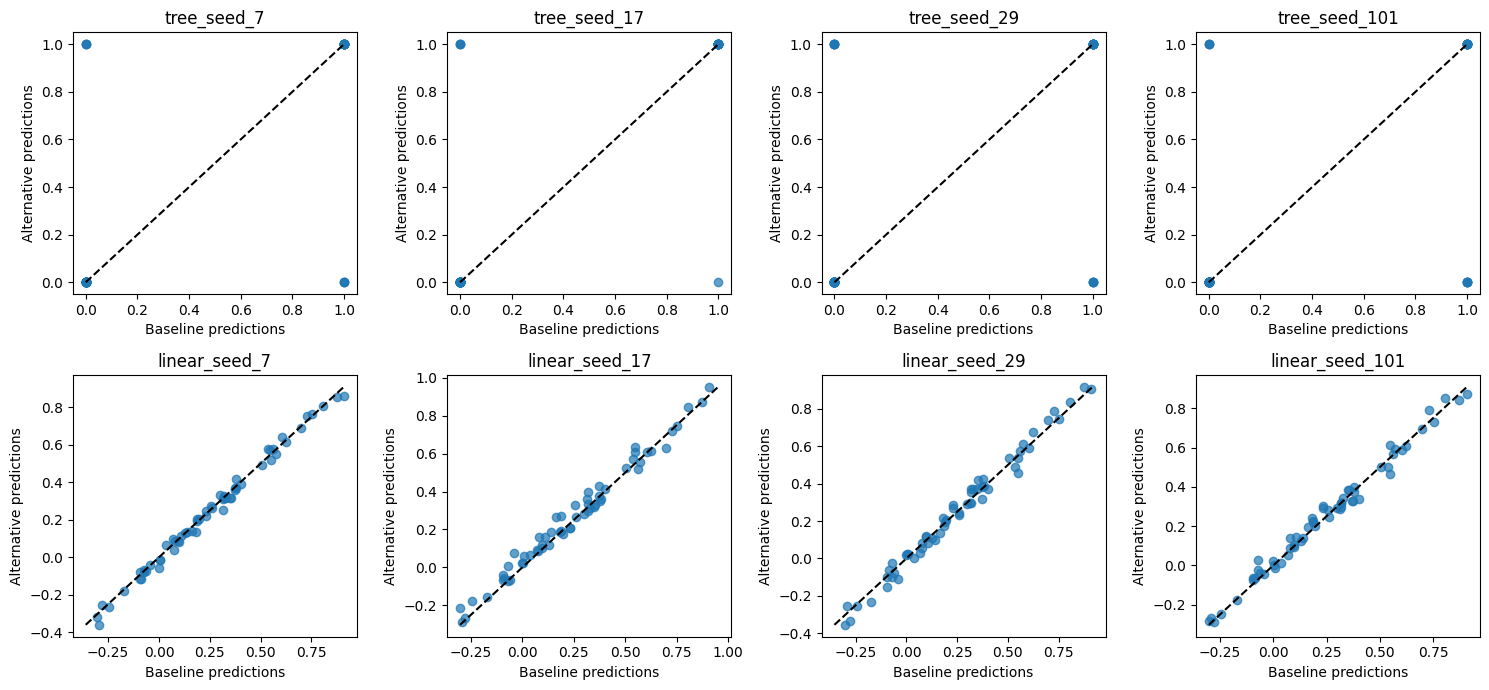

,correlation,intercept,slope,R-squared
model,,,,
tree_seed_7,0.733,0.067,0.733,0.538
tree_seed_17,0.833,0.067,0.867,0.694
tree_seed_29,0.609,0.111,0.622,0.371
tree_seed_101,0.631,0.067,0.600,0.398
linear_seed_7,0.997,-0.008,1.011,0.993
linear_seed_17,0.991,0.031,0.958,0.983
linear_seed_29,0.994,-0.008,1.037,0.987
linear_seed_101,0.993,0.015,0.971,0.987


In [10]:
q4_results = []

fig, axes = plt.subplots(2, len(alternative_seeds), figsize=(15, 7))

for row, model_type in enumerate(["tree", "linear"]):
    baseline = predictions[f"{model_type}_seed_42"]

    for column, seed in enumerate(alternative_seeds):
        alternative_name = f"{model_type}_seed_{seed}"
        alternative = predictions[alternative_name]

        # Correlation and regression: alternative predictions on baseline predictions.
        prediction_model = LinearRegression()
        prediction_model.fit(baseline.to_frame(), alternative)

        q4_results.append({
            "model": alternative_name,
            "correlation": baseline.corr(alternative),
            "intercept": prediction_model.intercept_,
            "slope": prediction_model.coef_[0],
            "R-squared": prediction_model.score(
                baseline.to_frame(), alternative
            )
        })

        # Scatterplot.
        ax = axes[row, column]
        ax.scatter(baseline, alternative, alpha=0.7)

        low = min(baseline.min(), alternative.min())
        high = max(baseline.max(), alternative.max())
        ax.plot([low, high], [low, high], "k--")

        ax.set_title(alternative_name)
        ax.set_xlabel("Baseline predictions")
        ax.set_ylabel("Alternative predictions")

plt.tight_layout()
plt.show()

display(pd.DataFrame(q4_results).set_index("model").round(3))

### Q5 Comparing Model Stability

In [11]:
# Compare tree depth and number of leaves.
print("Tree structures:")
display(pd.DataFrame(tree_sizes).T)

# Compare linear regression coefficients across fits.
coefficient_table = pd.DataFrame(coefficients)

print("Linear regression coefficients:")
display(coefficient_table)

print("Coefficient ranges across fits:")
display(
    pd.DataFrame({
        "minimum": coefficient_table.min(axis=1),
        "maximum": coefficient_table.max(axis=1),
        "range": coefficient_table.max(axis=1) - coefficient_table.min(axis=1)
    }).sort_values("range", ascending=False)
)

Tree structures:


,depth,leaves
tree_seed_42,8,30
tree_seed_7,8,30
tree_seed_17,8,27
tree_seed_29,8,26
tree_seed_101,7,26


Linear regression coefficients:


,linear_seed_42,linear_seed_7,linear_seed_17,linear_seed_29,linear_seed_101
age,4.590087e-03,4.459853e-03,3.571117e-03,5.121701e-03,4.081200e-03
anaemia,1.367106e-02,1.345286e-02,3.769900e-02,3.200268e-03,-1.796243e-03
creatinine_phosphokinase,4.393988e-05,4.636318e-05,4.181451e-05,2.932278e-05,4.988654e-05
diabetes,7.357562e-02,8.299436e-02,6.912868e-02,7.287827e-02,4.806677e-02
ejection_fraction,-1.038726e-02,-1.122151e-02,-1.174853e-02,-8.933575e-03,-9.151916e-03
high_blood_pressure,3.825520e-03,-2.729595e-02,-1.962671e-02,1.039235e-02,-1.472918e-03
platelets,-1.521454e-07,-1.239002e-07,-5.365539e-08,-3.561449e-07,-3.434375e-07
serum_creatinine,9.379010e-02,8.246222e-02,1.078307e-01,8.625434e-02,7.709633e-02
serum_sodium,-2.891449e-03,-3.447783e-03,1.180311e-04,-5.830626e-03,-6.469955e-03
sex,-5.732381e-02,-9.400481e-02,-4.362730e-02,-1.887148e-02,-5.827898e-02


Coefficient ranges across fits:


,minimum,maximum,range
intercept,6.858063e-01,1.619805e+00,9.339984e-01
smoking,-1.090542e-02,6.719559e-02,7.810102e-02
sex,-9.400481e-02,-1.887148e-02,7.513333e-02
anaemia,-1.796243e-03,3.769900e-02,3.949524e-02
high_blood_pressure,-2.729595e-02,1.039235e-02,3.768830e-02
diabetes,4.806677e-02,8.299436e-02,3.492759e-02
serum_creatinine,7.709633e-02,1.078307e-01,3.073433e-02
serum_sodium,-6.469955e-03,1.180311e-04,6.587986e-03
ejection_fraction,-1.174853e-02,-8.933575e-03,2.814958e-03
age,3.571117e-03,5.121701e-03,1.550584e-03


### Q6

For this dataset, I would say the statement is false for the decision trees, but true for the linear models. The tree predictions were only moderately similar across splits: their correlations ranged from 0.609 to 0.833, and their R-squared values ranged from 0.371 to 0.694. The linear model predictions were much more consistent, with correlations above 0.99 and slopes close to 1. Therefore, a model's appearance may change without greatly changing its predictions, but that was much more true for the linear models than for the trees in my results.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]